# Face-similarity metric: invariance envelope and AdaFace A/B

Results notebook for two measurements on the saved synthetic Maya album. It reads
the committed artifacts only — it does not re-run inference, and it needs no model
weights, API keys, or network access.

> **How to run** (from the repository root):
> ```sh
> uv pip install --python evaluation/.venv -r evaluation/notebook-requirements.txt
> evaluation/.venv/bin/jupyter lab evaluation/face_metric_results.ipynb
> ```

**Contents**

1. How far the ArcFace cosine moves when identity provably does not change.
2. The noise floor `T`, and how much of an identity swap nuisance consumes.
3. Whether the `iteration_01` claim survives that envelope — plus one caveat about
   how *not* to use `T`.
4. A controlled ArcFace-vs-AdaFace swap, holding detection, alignment and pairing fixed.

**Not claimed here:** cosine similarity is not a probability and there is no
calibrated identity threshold. Nothing below measures human-perceived identity, and
no image-generation quality claim follows from any of it.

**Provenance.** `results_invariance/invariance.json` and `results_adaface/ab_scores.json`
record input and weight SHA-256 hashes, package versions, frozen grids and settings.
The ArcFace arm re-derives the frozen `results/scores.json` baseline to 6.7e-16, so
all four files describe the same crop, the same detection and the same pairing rule.

The future-work backlog that this notebook motivates lives in
[`FUTURE_WORK.md`](FUTURE_WORK.md).

In [1]:
import csv, json, re
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from IPython.display import Markdown, display

# Locate evaluation/ whether the notebook is run from the repo root or from evaluation/.
def find_eval_dir() -> Path:
    for p in [Path.cwd(), *Path.cwd().parents]:
        for cand in (p / "results_invariance", p / "evaluation" / "results_invariance"):
            if cand.is_dir():
                return cand.parent
    raise SystemExit("Could not locate evaluation/results_invariance — run from the repository.")

EVAL = find_eval_dir()
INV_DIR, AB_DIR = EVAL / "results_invariance", EVAL / "results_adaface"

inv = json.loads((INV_DIR / "invariance.json").read_text())
curves = list(csv.DictReader((INV_DIR / "curves.csv").open()))
it01 = list(csv.DictReader((INV_DIR / "iteration01_check.csv").open()))
ab = json.loads((AB_DIR / "ab_scores.json").read_text())

IDENTITIES = ("maya", "priya", "jonah")


def md_table(headers, rows):
    out = ["| " + " | ".join(headers) + " |", "|" + "|".join(["---"] * len(headers)) + "|"]
    out += ["| " + " | ".join(str(c) for c in r) + " |" for r in rows]
    return "\n".join(out)


def worst_identity_drop(row):
    # Largest single-identity cosine drop in a curve row (matches the T definition).
    vals = [1 - float(row[f"cosine_person_{i}"]) for i in IDENTITIES if row.get(f"cosine_person_{i}")]
    return max(vals) if vals else float("nan")


print(f"evaluation dir : {EVAL}")
print(f"curve rows     : {len(curves)}   grid cells: {inv['grid_counts']}")
print(f"floor T        : {inv['floor']['T']:.4f}   (worst cell: {inv['floor']['driving_level']})")
print(f"runtime        : {inv['runtime_seconds']:.1f}s   generation calls: {inv['generation_calls']}")

evaluation dir : /Users/alistairking/Projects/upenn-courses/cis-5810/ai-camera-roll/evaluation
curve rows     : 146   grid cells: {'illumination': 18, 'none': 1, 'occlusion': 10, 'pose': 30, 'resolution': 14}
floor T        : 0.2997   (worst cell: eyes_10pct)
runtime        : 24.0s   generation calls: 0


## 1. How far does the score move when identity does not change?

Every perturbation is applied to a canonical portrait whose identity is unchanged by
construction, so **all** observed movement is metric sensitivity. Two regimes are
reported because they answer different questions:

- **end to end** — perturb the full portrait, then re-run SCRFD → `norm_crop` → ArcFace.
  This is what `score_faces.py` actually does, so it is the number that applies.
- **embed only** — perturb the already-aligned 112×112 crop and embed. Isolates the
  embedder from the aligner.

In [2]:
FAMILY_ORDER = [
    ("illumination", "gamma"), ("illumination", "shading"), ("illumination", "gain_offset"),
    ("resolution", "jpeg"), ("resolution", "blur"), ("illumination", "temperature"),
    ("pose", "roll"), ("pose", "yaw"), ("occlusion", "mouth"),
    ("resolution", "downscale"), ("pose", "pitch"), ("occlusion", "eyes"),
]

tier = inv["realistic_tier"]
realistic = [r for r in curves if r["realistic"] == "True" and r["family"] != "none"]
worst = {}
for r in realistic:
    key = (r["regime"], r["subfamily"])
    d = worst_identity_drop(r)
    if key not in worst or d > worst[key]["drop"]:
        worst[key] = {"drop": d, "level": r["level"], "mean": float(r["mean_drop"])}

rows = []
for fam, sub in FAMILY_ORDER:
    e, b = worst.get(("end_to_end", sub)), worst.get(("embed_only", sub))
    rows.append([
        fam, sub,
        f"{e['drop']:.3f}" if e else "—", e["level"] if e else "—",
        f"{b['drop']:.3f}" if b else "—",
    ])

display(Markdown(
    "**Realistic tier only** (the frozen rule: pose ≤ 20°, gamma 0.7–1.4, gain 0.8–1.25, "
    "short side ≥ 160 px, blur ≤ σ1, JPEG ≥ q50, occlusion ≤ 10 % of the face box).\n\n"
    "Worst-single-identity cosine **drop** within that tier, sorted by cost. "
    "Larger = the metric is less invariant to that nuisance.\n\n"
    + md_table(["family", "sub-family", "end-to-end drop", "worst realistic level", "embed-only drop"], rows)
))

**Realistic tier only** (the frozen rule: pose ≤ 20°, gamma 0.7–1.4, gain 0.8–1.25, short side ≥ 160 px, blur ≤ σ1, JPEG ≥ q50, occlusion ≤ 10 % of the face box).

Worst-single-identity cosine **drop** within that tier, sorted by cost. Larger = the metric is less invariant to that nuisance.

| family | sub-family | end-to-end drop | worst realistic level | embed-only drop |
|---|---|---|---|---|
| illumination | gamma | 0.008 | gamma_1.4 | 0.005 |
| illumination | shading | 0.030 | shading_0.5_at_90deg | 0.113 |
| illumination | gain_offset | 0.056 | gain_1.25_offset_+20 | 0.049 |
| resolution | jpeg | 0.034 | jpeg_q50 | 0.111 |
| resolution | blur | 0.022 | blur_sigma_1 | 0.087 |
| illumination | temperature | 0.072 | temperature_3000K | 0.067 |
| pose | roll | 0.032 | roll+10 | 0.360 |
| pose | yaw | 0.091 | yaw+20 | 0.098 |
| occlusion | mouth | 0.261 | mouth_10pct | 0.222 |
| resolution | downscale | 0.250 | downscale_160px | 0.000 |
| pose | pitch | 0.236 | pitch+20 | 0.205 |
| occlusion | eyes | 0.300 | eyes_10pct | 0.294 |

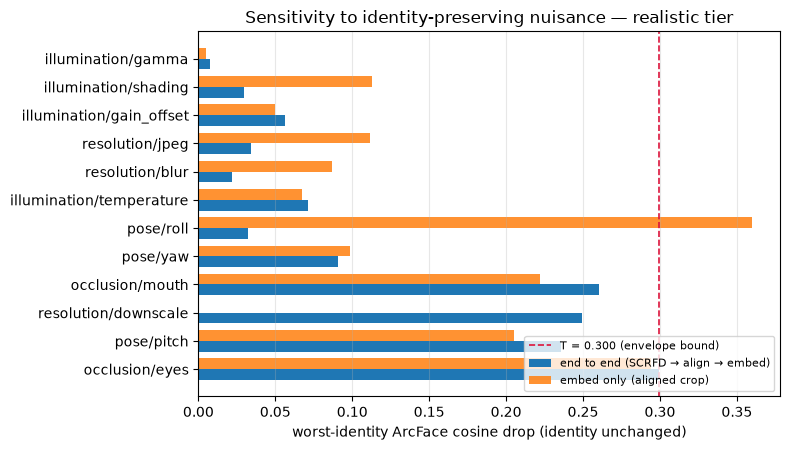

In [3]:
fig, ax = plt.subplots(figsize=(8.0, 4.6))
y = np.arange(len(FAMILY_ORDER))
e_vals = [worst.get(("end_to_end", s), {}).get("drop", np.nan) for _, s in FAMILY_ORDER]
b_vals = [worst.get(("embed_only", s), {}).get("drop", np.nan) for _, s in FAMILY_ORDER]
h = 0.38
ax.barh(y + h / 2, e_vals, h, label="end to end (SCRFD → align → embed)", color="#1f77b4")
ax.barh(y - h / 2, b_vals, h, label="embed only (aligned crop)", color="#ff7f0e", alpha=0.85)
ax.set_yticks(y)
ax.set_yticklabels([f"{f}/{s}" for f, s in FAMILY_ORDER])
ax.invert_yaxis()
ax.set_xlabel("worst-identity ArcFace cosine drop (identity unchanged)")
ax.set_title("Sensitivity to identity-preserving nuisance — realistic tier")
ax.axvline(inv["floor"]["T"], color="crimson", ls="--", lw=1.2,
           label=f"T = {inv['floor']['T']:.3f} (envelope bound)")
ax.legend(loc="lower right", fontsize=8)
ax.grid(axis="x", alpha=0.3)
fig.tight_layout()
plt.show()

Reading it:

- **Photometric change is nearly free.** Gamma, shading, gain and even a 3000 K colour
  cast cost ≤ 0.072. Illumination normalisation would be wasted effort.
- **The aligner absorbs roll.** Rolling the photo 20° costs 0.026 end to end but 0.329
  embed-only — a 12× difference that is a property of `norm_crop`, not of ArcFace.
- **Pose is not invariant, and it is asymmetric.** Pitch is roughly 2.5× costlier than
  yaw at the same angle.
- **Occlusion and resolution are the real failure modes**, and neither is something the
  face-recognition literature leads you to expect from a 512-d embedding.

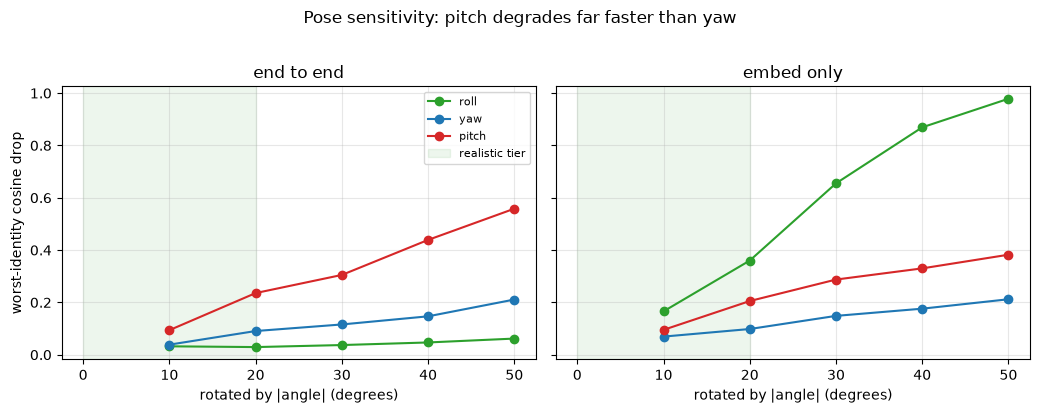

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(10.5, 4.0), sharey=True)
for ax, regime, label in zip(axes, ("end_to_end", "embed_only"), ("end to end", "embed only")):
    for sub, color in (("roll", "#2ca02c"), ("yaw", "#1f77b4"), ("pitch", "#d62728")):
        pts = {}
        for r in curves:
            if r["regime"] != regime or r["family"] != "pose" or r["subfamily"] != sub:
                continue
            deg = int(re.search(r"([+-]?\d+)$", r["level"]).group(1))
            pts[abs(deg)] = max(pts.get(abs(deg), 0.0), worst_identity_drop(r))
        xs = sorted(pts)
        ax.plot(xs, [pts[x] for x in xs], "o-", color=color, label=sub)
    ax.axvspan(0, 20, color="green", alpha=0.07, label="realistic tier")
    ax.set_title(label)
    ax.set_xlabel("rotated by |angle| (degrees)")
    ax.grid(alpha=0.3)
axes[0].set_ylabel("worst-identity cosine drop")
axes[0].legend(fontsize=8)
fig.suptitle("Pose sensitivity: pitch degrades far faster than yaw", y=1.02)
fig.tight_layout()
plt.show()

The pose sweep uses a **planar homography**, so the far cheek never self-occludes and
shading is unchanged, while SCRFD re-detected 5 landmarks in every cell (all 219
photo cells were detected). Real 3D rotation forces a profile view, so these pose
numbers are a **lower bound** on the true sensitivity.

## 2. The floor `T`, and the signal-to-noise ratio

`T` is the largest cosine drop any single identity showed under a **realistic**
perturbation in the **end-to-end** regime — a bound, not an average. It is computed
from the *verified* reference-vs-reference comparison described above.

In [5]:
f, b = inv["floor"], inv["between_identity"]
rows = [
    ["`T` (realistic, end-to-end, worst cell)", f"{f['T']:.4f}", f"driving cell: {f['driving_level']}"],
    ["`S_floor` = 1 − `T`", f"{f['S_floor']:.4f}", "lowest same-identity cosine seen"],
    ["`T` p90 / median", f"{f['T_p90']:.4f} / {f['T_median']:.4f}", "typical, not worst case"],
    ["`T` excluding occlusion", f"{f['T_without_occlusion']:.4f}", "the occlusion tier line is a judgement call"],
    ["`T` all cells (incl. harsh)", f"{f['T_all']:.4f}", "worst cell is a 40 px downscale"],
    ["realistic cells / all cells", f"{f['realistic_cells']} / {f['all_cells']}", ""],
    ["hardest impostor cosine", f"{b['max_cross_identity_cosine']:.4f}", "maya–priya"],
    ["identity-swap drop (hardest pair)", f"{b['identity_swap_drop_hardest']:.4f}", "1 − hardest impostor"],
    ["**nuisance share of an identity swap**", f"**{b['nuisance_share']:.0%}**", f"S/N = {b['ratio']:.2f}"],
]
display(Markdown(md_table(["quantity", "value", "note"], rows)))

| quantity | value | note |
|---|---|---|
| `T` (realistic, end-to-end, worst cell) | 0.2997 | driving cell: eyes_10pct |
| `S_floor` = 1 − `T` | 0.7003 | lowest same-identity cosine seen |
| `T` p90 / median | 0.1557 / 0.0241 | typical, not worst case |
| `T` excluding occlusion | 0.2496 | the occlusion tier line is a judgement call |
| `T` all cells (incl. harsh) | 1.0195 | worst cell is a 40 px downscale |
| realistic cells / all cells | 111 / 216 |  |
| hardest impostor cosine | 0.2588 | maya–priya |
| identity-swap drop (hardest pair) | 0.7412 | 1 − hardest impostor |
| **nuisance share of an identity swap** | **40%** | S/N = 2.47 |

**`T ≈ 0.30`, while a full identity swap only moves the score `0.74`.** Nuisance
therefore consumes about **40 % of the available signal**. Any claim that one
condition beats another must clear roughly 0.30 before it means anything.

This is also why the reference-vs-reference regime is not a gate for the scene faces
(see the caveat in §3).

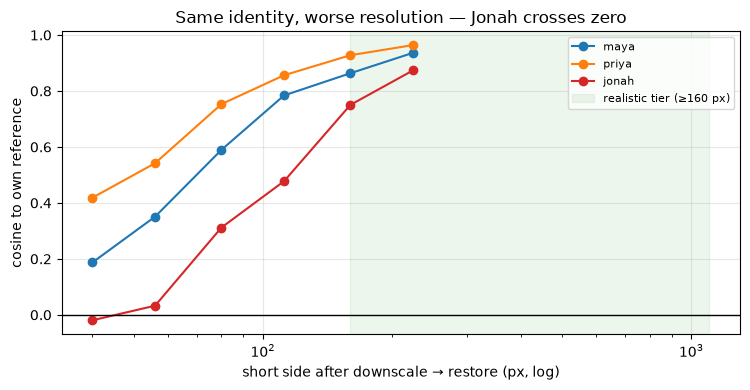

Jonah at 40 px: cosine = -0.020  (a same-identity pair scoring below an impostor)


In [6]:
fig, ax = plt.subplots(figsize=(7.6, 4.0))
for ident, color in zip(IDENTITIES, ("#1f77b4", "#ff7f0e", "#d62728")):
    xs, ys = [], []
    for r in curves:
        if r["regime"] == "end_to_end" and r["subfamily"] == "downscale":
            xs.append(int(re.search(r"(\d+)", r["level"]).group(1)))
            ys.append(float(r[f"cosine_person_{ident}"])) 
    o = np.argsort(xs)
    ax.plot(np.array(xs)[o], np.array(ys)[o], "o-", color=color, label=ident)
ax.axhline(0, color="black", lw=1)
ax.axvspan(160, 1100, color="green", alpha=0.07, label="realistic tier (≥160 px)")
ax.set_xscale("log")
ax.set_xlabel("short side after downscale → restore (px, log)")
ax.set_ylabel("cosine to own reference")
ax.set_title("Same identity, worse resolution — Jonah crosses zero")
ax.legend(fontsize=8)
ax.grid(alpha=0.3)
fig.tight_layout()
plt.show()

print("Jonah at 40 px: cosine = %.3f  (a same-identity pair scoring below an impostor)"
      % [float(r["cosine_person_jonah"]) for r in curves
         if r["regime"] == "end_to_end" and r["subfamily"] == "downscale"
         and r["level"].endswith("40px")][0])

Jonah has the smallest face in the pilot (91×118 px bounding box versus Maya's
145×182), so his fragility is systematic rather than noise: **resolution is a
confound that scales with how large the character happens to be in the frame.**

## 3. Does the `iteration_01` claim survive?

The claim under test: *in the historical pilot, Maya's assigned ArcFace similarity
fell after the second pass in all four multi-pass scenes.*

In [7]:
rows = []
for r in it01:
    drop = float(r["drop"])
    verdict = "exceeds T" if r["exceeds_T"] == "True" else "inside envelope"
    if r["exceeds_T"] == "True" and r["exceeds_2T"] != "True":
        verdict += " (tie)"
    rows.append([r["condition"], r["month"], f"{float(r['pass1']):.3f}", f"{float(r['pass2']):.3f}",
                 f"{drop:+.4f}", verdict])
display(Markdown(md_table(["condition", "month", "pass 1", "pass 2", "drop", "vs T = 0.30"], rows)))

| condition | month | pass 1 | pass 2 | drop | vs T = 0.30 |
|---|---|---|---|---|---|
| historical | 1 | 0.446 | 0.145 | +0.3003 | exceeds T (tie) |
| historical | 2 | 0.308 | 0.062 | +0.2463 | inside envelope |
| historical | 8 | 0.342 | 0.223 | +0.1188 | inside envelope |
| historical | 10 | 0.109 | 0.057 | +0.0516 | inside envelope |
| control | 1 | 0.312 | 0.155 | +0.1565 | inside envelope |
| control | 2 | 0.197 | 0.091 | +0.1063 | inside envelope |
| control | 8 | 0.100 | 0.073 | +0.0276 | inside envelope |
| control | 10 | 0.128 | 0.128 | -0.0007 | inside envelope |
| portrait_reference | 1 | 0.312 | 0.250 | +0.0622 | inside envelope |
| portrait_reference | 2 | 0.197 | 0.174 | +0.0230 | inside envelope |
| portrait_reference | 8 | 0.100 | 0.111 | -0.0104 | inside envelope |
| portrait_reference | 10 | 0.128 | 0.204 | -0.0762 | inside envelope |

**The direction reproduces; the magnitude does not support identity loss.**

- Jan drops 0.3003 against `T` = 0.2997 — it misses the envelope by **6 × 10⁻⁴**. That
  is a tie, not a separation.
- Feb (0.246), Aug (0.119) and Oct (0.052) are all **inside** the envelope.
- In the fresh control the October score actually **rose** (+0.0007).
- The `portrait_reference` October "drop" of −0.076 is **confounded** by the matcher
  switching its face assignment from 0 to 1, so it is not a like-for-like comparison.

### Caveat: `T` is a delta budget, not an absolute gate

`results_invariance/assignment_verdicts.csv` carries a `drop_from_perfect` column
(`1 − cosine`) that labels all 22 scene assignments `beyond_envelope`. **That framing
is a category error and should not be quoted.** `T` was measured on *reference versus a
perturbed copy of that same reference*, whose baseline is 1.0. A generated scene face
is a different rendering entirely and was never going to sit at 1.0, so the absolute
gate is guaranteed to fail for every face and carries no information about identity.

The valid use of `T` is the **difference between two conditions**, which is what the
table above does. Fixing the absolute question needs a matched baseline — the aligned
112×112 crops in both results directories already make that computable. See
[`FUTURE_WORK.md`](FUTURE_WORK.md#a1-matched-generated-vs-generated-baseline).

## 4. ArcFace vs AdaFace, with everything else held fixed

One detection pass per image feeds both arms, on the identical 112×112 aligned crop.
Detection, alignment, crop, ordering, references and the Hungarian pairing rule are
shared, so the only controlled variable is the embedding model (IR-101 @ WebFace12M)
and its input normalisation.

In [8]:
rows = []
for i, name in enumerate(ab["matrix_row_order"]):
    arc = ab["reference_cosine_matrix"]["arcface"][i]
    ada = ab["reference_cosine_matrix"]["adaface"][i]
    rows.append([name.replace("person_", "")]
                + [f"{c:.3f}" for c in arc if c < 0.99]
                + [f"{c:.3f}" for c in ada if c < 0.99])
others = [n.replace("person_", "") for n in ab["matrix_row_order"]]
display(Markdown(
    "**Reference inter-identity cosine.** The gallery is as tightly packed under AdaFace "
    "as under ArcFace, so the swap does not buy separation.\n\n"
    + md_table(["", *[f"Arc {o}" for o in others], *[f"Ada {o}" for o in others]], rows)))

dl = ab["comparison"]["similarity_delta_adaface_minus_arcface"]
dc = ab["comparison"]["detection_control"]
bc = ab["comparison"]["baseline_check"]
rows = [
    ["assigned similarity Δ (AdaFace − ArcFace)", f"mean {dl['mean']:+.4f}, median {dl['median']:+.4f}",
     f"range {dl['min']:+.3f} … {dl['max']:+.3f}"],
    ["Spearman ρ, all 66 reference×face cells", f"{ab['comparison']['spearman_all_cosine_cells']:.3f}", "the two models broadly agree"],
    ["Spearman ρ, assigned similarities", f"{ab['comparison']['spearman_assigned_similarities']:.3f}", ""],
    ["assignments changed", f"{ab['comparison']['assignment_change_count']} of 22",
     "all in October pass 2"],
    ["ArcFace arm vs frozen baseline", f"{bc['max_abs_cosine_deviation']:.1e}", f"detections identical: {bc['detections_identical']}"],
]
display(Markdown(md_table(["check", "value", "note"], rows)))

display(Markdown("**Assignment changes**\n\n" + md_table(
    ["month", "pass", "person", "ArcFace face", "AdaFace face"],
    [[c["month"], c["pass_index"], c["person_id"].replace("person_", ""),
      str(c["arcface_face_index"]).replace("None", "unassigned"),
      str(c["adaface_face_index"]).replace("None", "unassigned")]
     for c in ab["comparison"]["assignment_changes"]])))

**Reference inter-identity cosine.** The gallery is as tightly packed under AdaFace as under ArcFace, so the swap does not buy separation.

|  | Arc maya | Arc priya | Arc jonah | Ada maya | Ada priya | Ada jonah |
|---|---|---|---|---|---|---|
| maya | 0.259 | 0.208 | 0.248 | 0.212 |
| priya | 0.259 | 0.060 | 0.248 | 0.069 |
| jonah | 0.208 | 0.060 | 0.212 | 0.069 |

| check | value | note |
|---|---|---|
| assigned similarity Δ (AdaFace − ArcFace) | mean -0.0340, median -0.0391 | range -0.089 … +0.045 |
| Spearman ρ, all 66 reference×face cells | 0.821 | the two models broadly agree |
| Spearman ρ, assigned similarities | 0.939 |  |
| assignments changed | 3 of 22 | all in October pass 2 |
| ArcFace arm vs frozen baseline | 6.7e-16 | detections identical: True |

**Assignment changes**

| month | pass | person | ArcFace face | AdaFace face |
|---|---|---|---|---|
| 10 | 1 | maya | 0 | unassigned |
| 10 | 1 | priya | unassigned | 1 |
| 10 | 1 | jonah | 1 | 0 |

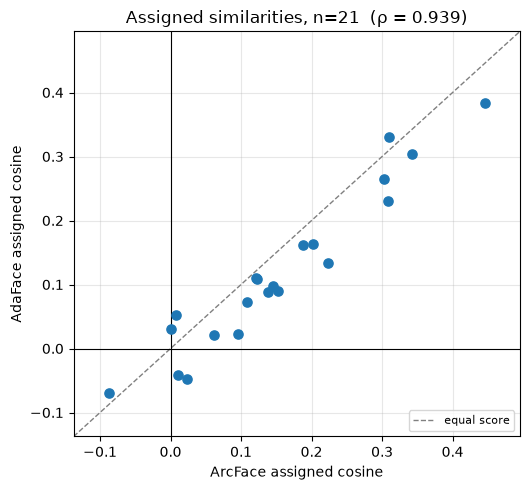

assignments with rank-1 margin below 0.07 — ArcFace 0/22, AdaFace 0/22


In [9]:
pairs = ab["comparison"]["scored_pairs"]
a = np.array([p["arcface_similarity"] for p in pairs])
b = np.array([p["adaface_similarity"] for p in pairs])
fig, ax = plt.subplots(figsize=(5.4, 5.0))
ax.scatter(a, b, s=44, color="#1f77b4", zorder=3)
lim = [min(a.min(), b.min()) - 0.05, max(a.max(), b.max()) + 0.05]
ax.plot(lim, lim, "--", color="grey", lw=1, label="equal score")
ax.axhline(0, color="black", lw=0.8); ax.axvline(0, color="black", lw=0.8)
ax.set_xlim(lim); ax.set_ylim(lim)
ax.set_xlabel("ArcFace assigned cosine"); ax.set_ylabel("AdaFace assigned cosine")
ax.set_title(f"Assigned similarities, n={len(pairs)}  (ρ = {ab['comparison']['spearman_assigned_similarities']:.3f})")
ax.legend(fontsize=8); ax.grid(alpha=0.3)
fig.tight_layout()
plt.show()

arc_m = sum(1 for p in ab["comparison"]["pass_to_pass_transitions"] if p.get("arcface_rank1_margin") is not None and abs(p["arcface_rank1_margin"]) < 0.07)
ada_m = sum(1 for p in ab["comparison"]["pass_to_pass_transitions"] if p.get("adaface_rank1_margin") is not None and abs(p["adaface_rank1_margin"]) < 0.07)
print(f"assignments with rank-1 margin below 0.07 — ArcFace {arc_m}/22, AdaFace {ada_m}/22")

In [10]:
sw = ab["preprocessing_sweep"]
rows = []
for c in sw["candidates"]:
    same = c["same_index_across_passes_mean"]
    diff = c["different_index_across_passes_mean"]
    ref_max = max(c["reference_inter_identity_cosines"])
    flag = "degenerate — every pair looks identical" if ref_max > 0.5 else "usable"
    rows.append([c["candidate"], c["channel_order"], f"(x−{c['mean']:g})/{c['std']:g}",
                 f"{same:.3f}", f"{diff:.3f}", f"{ref_max:.3f}", flag])
display(Markdown(
    f"**Preprocessing validation.** Selected: `{sw['selected']}` on training-convention "
    "grounds — not because it scored best on 22 pairs, which would be tuning on the "
    "evaluation set. A wrong normalisation is caught here rather than silently reported "
    "as a result.\n\n"
    + md_table(["candidate", "order", "normalisation", "same-position", "diff-position",
                "max ref inter-id", "status"], rows)))

**Preprocessing validation.** Selected: `rgb_symmetric_127.5` on training-convention grounds — not because it scored best on 22 pairs, which would be tuning on the evaluation set. A wrong normalisation is caught here rather than silently reported as a result.

| candidate | order | normalisation | same-position | diff-position | max ref inter-id | status |
|---|---|---|---|---|---|---|
| rgb_symmetric_127.5 | RGB | (x−127.5)/127.5 | 0.385 | 0.019 | 0.248 | usable |
| bgr_symmetric_127.5 | BGR | (x−127.5)/127.5 | 0.375 | 0.007 | 0.301 | usable |
| rgb_imagenet | RGB | (x−123.675)/58.395 | 0.497 | 0.056 | 0.169 | usable |
| rgb_unit | RGB | (x−0)/255 | 0.394 | 0.027 | 0.239 | usable |
| rgb_unscaled | RGB | (x−0)/1 | 0.975 | 0.836 | 0.928 | degenerate — every pair looks identical |

**Verdict: AdaFace is a lateral move here, not a fix.**

- Reference inter-identity separation is essentially unchanged.
- Assigned similarities are **slightly lower** on average, and margins get **worse**
  (more assignments fall inside the 0.07 near-tie band, and one more is negative).
- The claim does not flip anywhere: Maya falls pass 1 → pass 2 in Jan, Feb and Aug
  under **both** arms.
- It agrees with ArcFace on Maya (ρ = 0.94 on assigned pairs) but **disagrees on the
  supporting cast** — Jonah rises under AdaFace where he falls under ArcFace. That
  disagreement is itself a useful signal: Maya's drift is embedder-robust, the
  supporting characters' is not.

A quality-adaptive embedder cannot rescue a metric whose nuisance envelope is already
40 % of its signal. The bottleneck is the measurement design, not the model.

## 5. What follows

The measured bottleneck is **nuisance sensitivity and an uncalibrated absolute scale**,
not the choice of embedding model. Ranked next steps, with rationale, effort and
references, are tracked in [`FUTURE_WORK.md`](FUTURE_WORK.md). The three that follow
directly from this notebook:

1. **Matched baseline** — compute generated-vs-generated same-identity cosine from the
   saved aligned crops, which replaces the invalid `1 − cosine` gate in §3.
2. **Joint nuisances** — `T` is one-perturbation-at-a-time and therefore a lower bound;
   pose-and-occlusion together is the realistic case.
3. **Quality gating** — MagFace embedding norm or CR-FIQA, so coverage is reported next
   to every mean instead of averaging unwinnable comparisons into it.